# Project 2: Dijkstra's Algorithm

Implementation, theoretical analysis, reproducible experiments, and comparison.
Run all cells in order;
the tables, three plots, and final discussion update from the measured data.


The saved tables and plots are the measured reference run, preserved under
[recorded_results/](recorded_results/). Publication cleanup only changes
execution metadata, environment reporting and output-directory labels; the
algorithms, input generation and measurements are unchanged. Fresh runs use
unique directories under `results/`, which are ignored by Git.


#### Part (a) Setting: Graph G = (V, E) stored in an adjacency matrix and use an array for the priority queue

In [1]:
import math

def dijkstra_matrix(matrix, source):
    n = len(matrix)

    # Initiate shortest distance from souce to every other element to be infinitly
    dist = [math.inf] * n
    dist[source] = 0

    # Initiate all vertices havn't been visited
    visited = [False] * n
    
    # Traverse through every vertex
    for _ in range(n - 1):

        # Find the unvisited vertex with minimum distance using a priority queue (array)
        # Initiate the smallest distance vertex is not found
        u = -1
        for v in range(n):
            if not visited[v]:
                if u == -1 or dist[v] < dist[u]:
                    u = v
        # Remaining vertices are unreachable
        if u == -1 or dist[u] == math.inf:
            break
        
        visited[u] = True

        # Scan row of adjacency matrix
        for v in range(n):
            weight = matrix[u][v]
            
            # Check whether edge (u,v) exists
            if weight != math.inf and not visited[v]:
                new_dist = dist[u] + weight

                if new_dist < dist[v]:
                    dist[v] = new_dist

    return dist

#### Part (b) Setting: Graph G = (V, E) stored in an array of adjacency list and use a heap for the priority queue

In [2]:
import heapq
import math

def dijkstra_heap(graph, source):
    n = len(graph)

    # Initiate shortest distance from souce to every other element to be infinitly far
    dist = [math.inf] * n
    dist[source] = 0

    # Min-Heap stores (distance, vertex)
    heap = [(0, source)]

    while heap:
        curr_dist, u = heapq.heappop(heap)

        # Ignore the ones that provides longer distance in this round
        if curr_dist > dist[u]:
            continue

        # Find the shortest weight path
        for v, weight in graph[u]:
            new_dist = curr_dist + weight

            if new_dist < dist[v]:
                dist[v] = new_dist

                heapq.heappush(heap, (new_dist, v))
    return dist

### Theoretical analysis of (a) and (b)

Let $V$ and $E$ denote the numbers of vertices and directed edges. Vertices
are numbered $0,\ldots,V-1$. Edge weights must be nonnegative. The matrix
uses `math.inf` for an absent edge and zero on its diagonal. An adjacency
list contains `(neighbour, weight)` pairs. Both functions return distances;
unreachable vertices retain `math.inf`.

**(a) Matrix and array.** Each iteration scans all $V$ vertices to select the
smallest unvisited distance, then scans an entire matrix row. There are at
most $V-1$ iterations, so the worst-case time is $\Theta(V^2)$, including
when the input is sparse but all vertices are reachable. The algorithm uses
$O(V)$ auxiliary space; the matrix itself occupies $\Theta(V^2)$ space.
The last remaining vertex does not need to relax outgoing edges to obtain
the final distances, so the existing `range(n - 1)` is sufficient.

**(b) Adjacency lists and heap.** This implementation inserts a new heap
entry after each successful relaxation and skips old entries on removal.
It does not perform an indexed `decrease-key`. Each reachable vertex's
outgoing edges are scanned once, at most $E$ relaxations succeed, and the
heap can contain $O(E)$ entries. A suitable bound is
$O(V + E\log(E+1))$. For simple graphs, $E\leq V(V-1)$, giving
$O(V + E\log V)$ for $V\geq2$. Auxiliary space is $O(V+E)$ in the worst
case, including duplicate heap entries; adjacency-list storage is also
$O(V+E)$. These are upper bounds, not predictions of an exact runtime curve.

Graph construction and representation conversion are excluded from the
algorithm timings below. They have their own costs, including the
$\Theta(V^2)$ cost of constructing a matrix.

### Shared graph representations

Build both representations from the same edge list. Each `(u, v, weight)`
is one directed edge; the input must contain no parallel edges or self-loops.
The variable spelling in the original helper has been corrected to `weight`.

In [3]:
def build_graphs(n, edges):
    # edges contains (u, v, weight), with no duplicate edges
    matrix = [[math.inf] * n for _ in range(n)]
    graph = [[] for _ in range(n)]

    for u in range(n):
        matrix[u][u] = 0

    for u, v, weight in edges:
        matrix[u][v] = weight
        graph[u].append((v, weight))

    return matrix, graph

### Experiment settings and output files

Three experiment families separate different growth patterns:

| Experiment | Vertices | Edges | Purpose |
|---|---|---|---|
| Sparse scaling | 100, 200, 400, 800 | $E=4V$ | Increase $V$ with constant average out-degree |
| Dense scaling | 100, 200, 400, 800 | $E=\lfloor0.25V(V-1)\rfloor$ | Increase $V$ at constant density |
| Edge sweep | 400 | Densities 1%, 5%, 10%, 25%, 50%, 100% | Hold $V$ constant and change $E$ |

For a directed simple graph, density is $E/[V(V-1)]$. Edge weights are
integers sampled uniformly from 1 to 100. Five fixed seeds supply five
different graphs per setting. Each algorithm is warmed up once on each
graph, then measured three times. The two execution orders alternate.
Case order is shuffled with a separate fixed seed to reduce systematic
effects from running small or sparse cases first.

A point on a chart is the **median across five graphs of each graph's
three-run median**. Error bars show the minimum and maximum of those five
graph medians, not confidence intervals. Speedups use the median of the
five paired ratios `matrix_time / heap_time`.

Run all cells from top to bottom. Each execution creates a new uniquely named
folder under `results/`, preserving earlier measurements. Dependencies:
Python, Jupyter/ipykernel, pandas, and matplotlib.

In [4]:
%matplotlib inline
import hashlib
import json
import platform
import random
from uuid import uuid4
from pathlib import Path
from time import perf_counter_ns, get_clock_info

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

VERTEX_COUNTS = [100, 200, 400, 800]
DENSITIES = [0.01, 0.05, 0.10, 0.25, 0.50, 1.00]
GRAPH_SEEDS = [2001, 2002, 2003, 2004, 2005]
REPEATS = 3
SOURCE = 0
WEIGHT_MIN, WEIGHT_MAX = 1, 100
CASE_ORDER_SEED = 20261005

if Path("Project_2.ipynb").is_file():
    PROJECT_DIR = Path.cwd()
elif Path("Project 2/Project_2.ipynb").is_file():
    PROJECT_DIR = Path("Project 2").resolve()
else:
    raise RuntimeError("Start Jupyter in the Project 2 directory or the labs directory.")

RUN_DIR = PROJECT_DIR / "results" / f"run_{uuid4().hex[:12]}"
FIGURE_DIR = RUN_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=False)
plt.rcParams.update({"font.size": 10, "figure.dpi": 120})
print("Output directory:", RUN_DIR.relative_to(PROJECT_DIR).as_posix())
print("Python:", platform.python_version(), "| Platform:", platform.system())

Output directory: recorded_results
Python: 3.13.7 | Platform: Windows


### Why these input graphs?

1. **Control both $V$ and $E$.** Sparse scaling keeps $E=4V$; dense scaling
   makes $E$ grow quadratically. A fixed-$V$ edge sweep isolates the effect
   of adding edges. Density is a way of specifying $E$, not a third
   independent graph-size variable.
2. **Control reachability.** Plant a random directed tree rooted at vertex 0
   before adding other edges. Every vertex is reachable from the source,
   so a small reachable component cannot accidentally make a large graph
   look cheap. This samples tree-augmented random graphs; it is **not** a
   uniform sample of all connected directed graphs.
3. **Compare identical inputs.** Both representations use exactly the same
   endpoints and weights. At a fixed $V$ and seed, denser graphs extend
   the same edge sequence and retain the weights of existing edges. Thus
   the density sweep adds edges without changing the old edges' weights.
4. **Keep weights controlled.** Positive weights satisfy Dijkstra's
   precondition and keep the weight distribution fixed across settings.
   Zero-weight edges and disconnected graphs are tested separately for
   correctness. Negative weights are outside this algorithm's contract.
5. **Measure variation and preserve reproducibility.** Five seeds vary graph
   structure, three repeats expose timing noise, and saved seeds, settings,
   raw times and graph hashes make the experiment auditable.

The generator shuffles candidate edge IDs once, avoiding slow rejection
sampling near 100% density. It enumerates $V(V-1)$ candidates even for a
sparse graph. This setup cost is deliberately outside algorithm timing;
this experiment does not measure end-to-end graph ingestion or memory use.

In [5]:
def generate_edges(n, edge_count, seed, source=0):
    """Generate exactly E unique directed edges, all vertices source-reachable.

    For the same n and seed, shorter outputs are prefixes of longer ones.
    """
    if n < 1 or not 0 <= source < n:
        raise ValueError("A nonempty graph and a valid source are required.")
    if not n - 1 <= edge_count <= n * (n - 1):
        raise ValueError("Require V-1 <= E <= V(V-1) for the reachable graphs.")

    topology_rng = random.Random(seed)
    weight_rng = random.Random(seed + 1_000_003)
    order = [v for v in range(n) if v != source]
    topology_rng.shuffle(order)
    order.insert(0, source)

    # Edge ID u*(n-1)+offset encodes every possible non-self edge once.
    tree_ids = set()
    for i in range(1, n):
        u = order[topology_rng.randrange(i)]
        v = order[i]
        offset = v if v < u else v - 1
        tree_ids.add(u * (n - 1) + offset)

    candidates = [i for i in range(n * (n - 1)) if i not in tree_ids]
    topology_rng.shuffle(candidates)
    selected = sorted(tree_ids) + candidates[:edge_count - len(tree_ids)]

    edges = []
    for edge_id in selected:
        u, offset = divmod(edge_id, n - 1)
        v = offset if offset < u else offset + 1
        edges.append((u, v, weight_rng.randint(WEIGHT_MIN, WEIGHT_MAX)))
    return edges

### Correctness checks before timing

Bellman-Ford provides an independent oracle on small graphs. Named tests
include a single vertex, no edges, disconnected components, zero-weight
cycles, equal shortest paths, and stale heap entries. Additional random
directed graphs include zero weights and test every possible source.
Generator checks verify edge counts, uniqueness, reachability, reproducible
weights and the nested-input property used in the density sweep.

In [6]:
def bellman_ford(n, edges, source):
    distances = [math.inf] * n
    distances[source] = 0
    for _ in range(n - 1):
        changed = False
        for u, v, weight in edges:
            candidate = distances[u] + weight
            if candidate < distances[v]:
                distances[v] = candidate
                changed = True
        if not changed:
            break
    return distances

named_cases = [
    ("single vertex", 1, []),
    ("no edges", 5, []),
    ("disconnected", 5, [(0, 1, 3), (1, 2, 4), (3, 4, 1)]),
    ("zero cycle", 4, [(0, 1, 0), (1, 2, 0), (2, 0, 0), (2, 3, 2)]),
    ("stale entries", 4, [(0, 1, 10), (0, 2, 1), (2, 1, 1), (1, 3, 1), (2, 3, 10)]),
    ("equal paths", 4, [(0, 1, 1), (0, 2, 1), (1, 3, 1), (2, 3, 1)]),
]
checks = 0

def check_distances(n, edges):
    matrix, graph = build_graphs(n, edges)
    for source in range(n):
        expected = bellman_ford(n, edges, source)
        assert dijkstra_matrix(matrix, source) == expected
        assert dijkstra_heap(graph, source) == expected
    return n

for name, n, edges in named_cases:
    checks += check_distances(n, edges)

test_rng = random.Random(7301)
for _ in range(100):
    n = test_rng.randint(2, 12)
    density = test_rng.choice([0.0, 0.1, 0.5, 1.0])
    edges = [(u, v, test_rng.randint(0, 20))
             for u in range(n) for v in range(n)
             if u != v and test_rng.random() < density]
    checks += check_distances(n, edges)

for n in [1, 2, 10]:
    for edge_count in sorted({n - 1, n * (n - 1)}):
        edges = generate_edges(n, edge_count, seed=2001)
        assert len(edges) == edge_count
        assert len({(u, v) for u, v, _ in edges}) == edge_count
        assert all(u != v and WEIGHT_MIN <= w <= WEIGHT_MAX for u, v, w in edges)
        matrix, graph = build_graphs(n, edges)
        expected = bellman_ford(n, edges, 0)
        assert all(math.isfinite(d) for d in expected)
        assert dijkstra_matrix(matrix, 0) == dijkstra_heap(graph, 0) == expected

small = generate_edges(10, 20, seed=2001)
large = generate_edges(10, 90, seed=2001)
assert small == large[:len(small)]
assert small == generate_edges(10, 20, seed=2001)
print(f"PASS: {checks} graph/source checks against Bellman-Ford.")
print("PASS: exact edge counts, unique edges, valid weights, reachability and nested inputs.")

PASS: 715 graph/source checks against Bellman-Ford.
PASS: exact edge counts, unique edges, valid weights, reachability and nested inputs.


### Run the three experiments

`perf_counter_ns` measures elapsed wall-clock time, converted to seconds.
Only the algorithm call is inside the timed region. Graph generation,
representation conversion, hashing, comparisons, printing, aggregation and
plotting are excluded. Normal Python garbage collection remains enabled
for both implementations. No algorithm-operation counters run inside the
timed functions. Every warm-up and measured output is checked for equality.

There are 14 settings, 5 seeds per setting and 3 repeats per algorithm:
**70 graph cases and 420 timed calls**, plus 140 untimed warm-up calls.
Some settings overlap across experiment families, so the graph cases are
not all distinct graphs. A shared $(V,E,seed)$ produces the same graph.

In [7]:
settings = []
for n in VERTEX_COUNTS:
    settings.append(("sparse_scaling", n, 4 * n))
    settings.append(("dense_scaling", n, n * (n - 1) // 4))
for density in DENSITIES:
    settings.append(("edge_sweep", 400, round(density * 400 * 399)))

cases = [(experiment, n, edge_count, seed)
         for experiment, n, edge_count in settings for seed in GRAPH_SEEDS]
random.Random(CASE_ORDER_SEED).shuffle(cases)
algorithms = {"matrix": dijkstra_matrix, "heap": dijkstra_heap}
records = []
graph_records = []
benchmark_start = perf_counter_ns()

for case_index, (experiment, n, edge_count, seed) in enumerate(cases):
    edges = generate_edges(n, edge_count, seed, SOURCE)
    matrix, graph = build_graphs(n, edges)
    assert len(edges) == edge_count
    graph_hash = hashlib.sha256(json.dumps(edges, separators=(",", ":")).encode()).hexdigest()
    inputs = {"matrix": matrix, "heap": graph}
    first_order = ["matrix", "heap"] if case_index % 2 == 0 else ["heap", "matrix"]

    # Untimed warm-up and agreement/reachability checks.
    warm = {name: algorithms[name](inputs[name], SOURCE) for name in first_order}
    assert warm["matrix"] == warm["heap"]
    assert all(math.isfinite(d) for d in warm["matrix"])
    graph_records.append({"experiment": experiment, "V": n, "E": edge_count,
                          "seed": seed, "source": SOURCE, "graph_sha256": graph_hash})

    for repeat in range(REPEATS):
        execution_order = first_order if repeat % 2 == 0 else first_order[::-1]
        for position, name in enumerate(execution_order, 1):
            start = perf_counter_ns()
            distances = algorithms[name](inputs[name], SOURCE)
            elapsed_ns = perf_counter_ns() - start
            correct = distances == warm["matrix"]
            assert correct, (experiment, n, edge_count, seed, repeat, name)
            records.append({
                "experiment": experiment, "V": n, "E": edge_count,
                "density": edge_count / (n * (n - 1)), "seed": seed,
                "repeat": repeat + 1, "order": position, "algorithm": name,
                "seconds": elapsed_ns / 1e9, "correct": correct,
                "case_order": case_index + 1,
            })
    if (case_index + 1) % 10 == 0:
        print(f"Completed {case_index + 1}/{len(cases)} graph cases")

raw = pd.DataFrame(records)
assert len(raw) == len(settings) * len(GRAPH_SEEDS) * REPEATS * 2
assert raw["correct"].all() and raw["seconds"].gt(0).all()
raw.to_csv(RUN_DIR / "raw_timings.csv", index=False)
pd.DataFrame(graph_records).to_csv(RUN_DIR / "graph_manifest.csv", index=False)
benchmark_elapsed = (perf_counter_ns() - benchmark_start) / 1e9
print(f"Saved {len(raw)} timed calls; all results agree.")
print(f"Benchmark loop including input setup: {benchmark_elapsed:.2f} seconds")

Completed 10/70 graph cases


Completed 20/70 graph cases


Completed 30/70 graph cases


Completed 40/70 graph cases


Completed 50/70 graph cases


Completed 60/70 graph cases


Completed 70/70 graph cases
Saved 420 timed calls; all results agree.
Benchmark loop including input setup: 12.57 seconds


In [8]:
group_columns = ["experiment", "V", "E", "density", "seed"]
per_graph = (raw.groupby(group_columns + ["algorithm"])["seconds"]
            .median().unstack("algorithm").reset_index())
per_graph.columns.name = None
per_graph = per_graph.rename(columns={"matrix": "matrix_seconds", "heap": "heap_seconds"})
per_graph["speedup"] = per_graph["matrix_seconds"] / per_graph["heap_seconds"]
per_graph.to_csv(RUN_DIR / "per_graph_medians.csv", index=False)

summary = (per_graph.groupby(group_columns[:-1], as_index=False).agg(
    matrix_seconds=("matrix_seconds", "median"),
    matrix_min=("matrix_seconds", "min"), matrix_max=("matrix_seconds", "max"),
    heap_seconds=("heap_seconds", "median"),
    heap_min=("heap_seconds", "min"), heap_max=("heap_seconds", "max"),
    speedup=("speedup", "median"), speedup_min=("speedup", "min"),
    speedup_max=("speedup", "max"), graphs=("seed", "count")))
assert len(summary) == len(settings) and summary["graphs"].eq(len(GRAPH_SEEDS)).all()
summary.to_csv(RUN_DIR / "summary.csv", index=False)

environment = {
    "python": platform.python_version(), "platform": platform.system(),
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "timer": "perf_counter_ns (elapsed wall time)",
    "timer_resolution_seconds": get_clock_info("perf_counter").resolution,
    "vertex_counts": VERTEX_COUNTS, "edge_sweep_vertices": 400,
    "densities": DENSITIES, "graph_seeds": GRAPH_SEEDS,
    "source": SOURCE, "repeats": REPEATS, "warmups": 1,
    "weight_range_inclusive": [WEIGHT_MIN, WEIGHT_MAX],
    "case_order_seed": CASE_ORDER_SEED,
    "generator": "random outward tree + shuffled remaining directed edges; nested by E",
    "settings": [{"experiment": name, "V": n, "E": e} for name, n, e in settings],
    "correctness_graph_source_checks": checks, "timed_calls": len(raw),
    "graph_cases": len(cases), "benchmark_loop_seconds": benchmark_elapsed,
    "summary": "median of five per-graph medians; each graph has three measured repeats",
    "error_bars": "min/max across five per-graph medians, not confidence intervals",
    "speedup": "median of five paired matrix/heap ratios",
    "limitations": "one machine; normal GC; warm runs; V<=800; tree-augmented positive-weight graphs",
}
(RUN_DIR / "environment.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")

for experiment, title in [("sparse_scaling", "Sparse scaling: E = 4V"),
                          ("dense_scaling", "Dense scaling: density = 25%"),
                          ("edge_sweep", "Edge sweep: V = 400")]:
    table = summary[summary["experiment"] == experiment].sort_values(["V", "E"]).copy()
    table["density_percent"] = table["density"] * 100
    table["matrix_ms"] = table["matrix_seconds"] * 1000
    table["heap_ms"] = table["heap_seconds"] * 1000
    display(Markdown(f"**{title}**"))
    display(table[["V", "E", "density_percent", "matrix_ms", "heap_ms", "speedup"]]
            .style.format({"density_percent": "{:.2f}", "matrix_ms": "{:.4f}",
                           "heap_ms": "{:.4f}", "speedup": "{:.2f}"}).hide(axis="index"))

**Sparse scaling: E = 4V**

V,E,density_percent,matrix_ms,heap_ms,speedup
100,400,4.04,0.5691,0.0429,13.95
200,800,2.01,2.2790,0.0937,24.41
400,1600,1.00,9.3789,0.4127,25.85
800,3200,0.50,38.2900,0.7420,53.52


**Dense scaling: density = 25%**

V,E,density_percent,matrix_ms,heap_ms,speedup
100,2475,25.00,0.6489,0.1361,4.99
200,9950,25.00,2.6191,0.4169,6.38
400,39900,25.00,10.9876,3.2405,3.39
800,159800,25.00,49.5843,23.5540,2.10


**Edge sweep: V = 400**

V,E,density_percent,matrix_ms,heap_ms,speedup
400,1596,1.00,9.2385,0.4387,21.61
400,7980,5.00,9.5269,0.9508,10.02
400,15960,10.00,10.0131,1.2876,7.80
400,39900,25.00,10.4959,3.5213,2.98
400,79800,50.00,12.7844,6.7442,1.97
400,159600,100.00,13.9591,16.4613,0.78


### Runtime plots

Both axes use logarithmic scales so both implementations remain visible
even when their times differ greatly. Each point uses the same aggregation
as the tables. The edge-sweep x-axis is the actual number of directed edges.

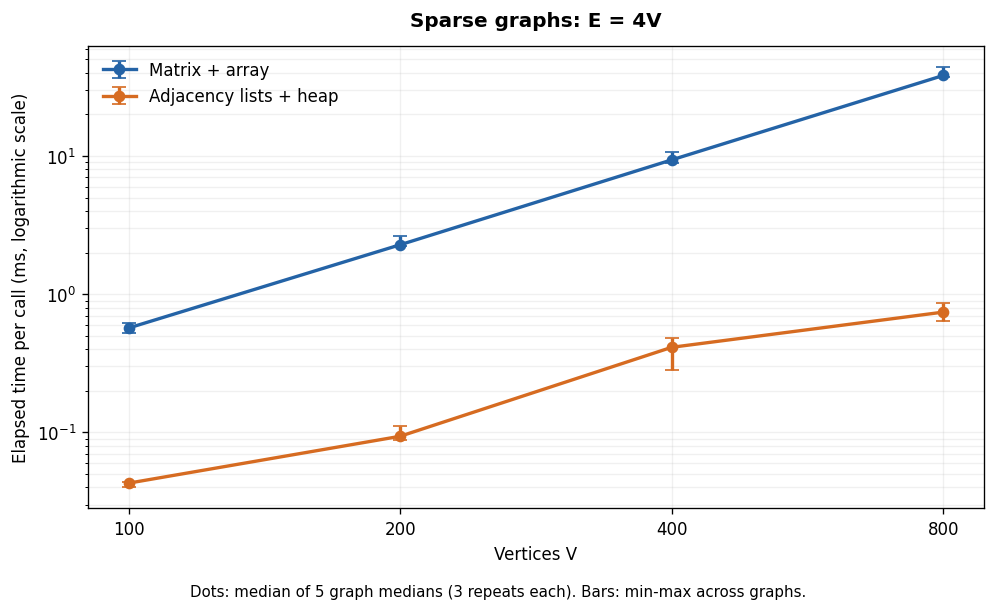

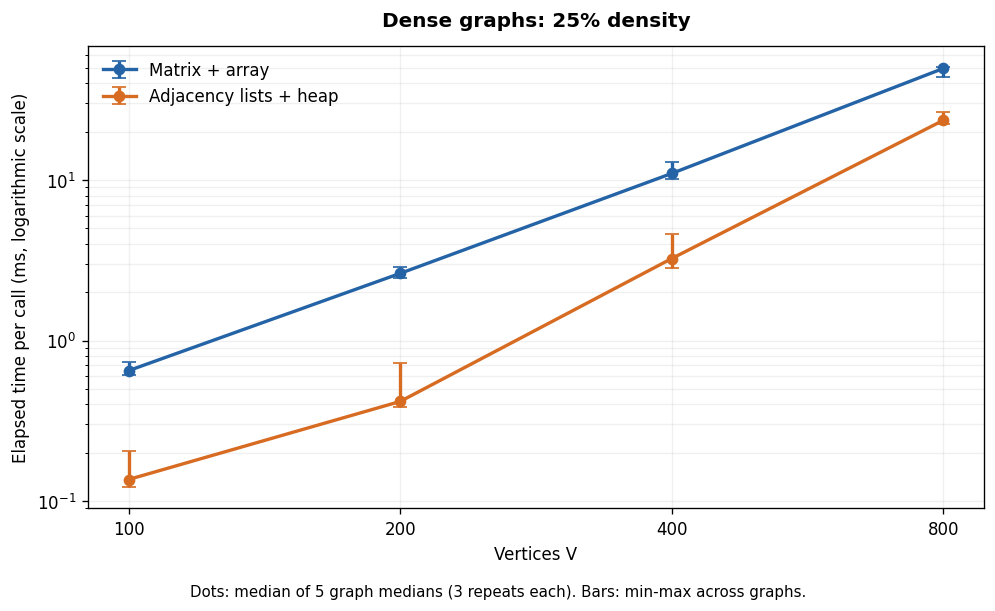

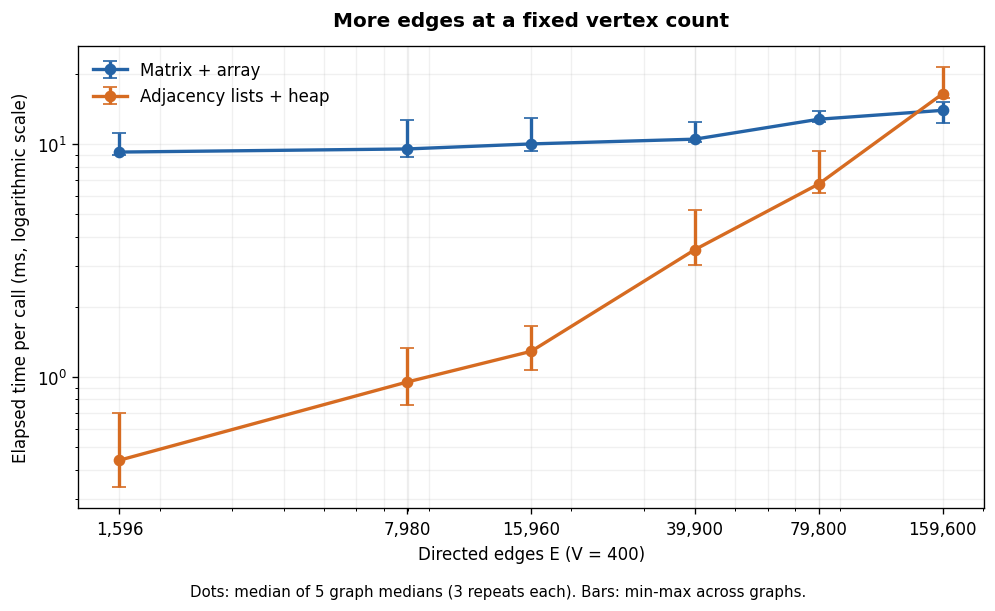

In [9]:
def plot_experiment(experiment, title, x_column, filename):
    data = summary[summary["experiment"] == experiment].sort_values(x_column)
    fig, ax = plt.subplots(figsize=(8.4, 5.1))
    for name, label, color in [("matrix", "Matrix + array", "#2463A6"),
                                ("heap", "Adjacency lists + heap", "#D66B21")]:
        center = data[f"{name}_seconds"] * 1000
        error = [center - data[f"{name}_min"] * 1000,
                 data[f"{name}_max"] * 1000 - center]
        ax.errorbar(data[x_column], center, yerr=error, fmt="o-", color=color,
                    label=label, capsize=4, linewidth=2, markersize=6)
    ax.set_xscale("log", base=2 if x_column == "V" else 10)
    ax.set_yscale("log")
    ax.set_xticks(data[x_column], [f"{int(value):,}" for value in data[x_column]])
    ax.set_xlabel("Vertices V" if x_column == "V" else "Directed edges E (V = 400)")
    ax.set_ylabel("Elapsed time per call (ms, logarithmic scale)")
    ax.set_title(title, pad=12, weight="bold")
    ax.grid(True, which="both", alpha=0.18)
    ax.legend(loc="best", frameon=False)
    fig.text(0.5, 0.015, "Dots: median of 5 graph medians (3 repeats each). Bars: min-max across graphs.",
             ha="center", fontsize=9)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.savefig(FIGURE_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

plot_experiment("sparse_scaling", "Sparse graphs: E = 4V", "V", "sparse_scaling.png")
plot_experiment("dense_scaling", "Dense graphs: 25% density", "V", "dense_scaling.png")
plot_experiment("edge_sweep", "More edges at a fixed vertex count", "E", "edge_sweep.png")

### Part (c): compare the measured implementations

The following discussion is generated from this run's saved summary so
rerunning the notebook updates both the tables and the conclusions.
A speedup greater than 1 means the heap implementation was faster.

Theory predicts quadratic matrix work on these reachable inputs. Sparse
$E=4V$ graphs give the heap version an $O(V\log V)$ upper bound, whereas
constant-density graphs give an $O(V^2\log V)$ upper bound. The latter
does not require the measured heap curve to grow as $V^2\log V$: scanning
edges can dominate, and many examined edges do not cause successful
relaxation or insertion into the heap.

Timing ratios describe these Python implementations, including their
loop structure and Python's `heapq` implementation. They do not isolate
a single language-independent data-structure cost. Four sizes and five
seeds illustrate trends; they do not establish an asymptotic bound.

In [10]:
sparse = summary[summary["experiment"] == "sparse_scaling"].sort_values("V")
dense = summary[summary["experiment"] == "dense_scaling"].sort_values("V")
sweep = summary[summary["experiment"] == "edge_sweep"].sort_values("E")
s0, s1 = sparse.iloc[0], sparse.iloc[-1]
d0, d1 = dense.iloc[0], dense.iloc[-1]
e0, e1 = sweep.iloc[0], sweep.iloc[-1]
faster_settings = int(summary["speedup"].gt(1).sum())
faster_graphs = int(per_graph["speedup"].gt(1).sum())

discussion = f"""
**Observed results.** The heap implementation was faster in {faster_settings}/{len(summary)}
settings by median paired ratio and {faster_graphs}/{len(per_graph)} graph cases by
per-graph median. All {len(raw)} timed outputs agreed.

- **Sparse graphs:** at V={int(s1.V)}, E={int(s1.E)}, matrix time was
  {s1.matrix_seconds * 1000:.3f} ms and heap time was {s1.heap_seconds * 1000:.3f} ms;
  the paired speedup was {s1.speedup:.2f}x. From V={int(s0.V)} to {int(s1.V)},
  matrix time increased {s1.matrix_seconds / s0.matrix_seconds:.2f}x and heap time
  increased {s1.heap_seconds / s0.heap_seconds:.2f}x.
- **Dense graphs (25%):** at V={int(d1.V)}, E={int(d1.E)}, matrix time was
  {d1.matrix_seconds * 1000:.3f} ms and heap time was {d1.heap_seconds * 1000:.3f} ms;
  the paired speedup was {d1.speedup:.2f}x. Across the same vertex range,
  matrix time increased {d1.matrix_seconds / d0.matrix_seconds:.2f}x and heap time
  increased {d1.heap_seconds / d0.heap_seconds:.2f}x.
- **Fixed V={int(e0.V)}:** increasing density from {e0.density:.0%} to {e1.density:.0%}
  changed matrix time from {e0.matrix_seconds * 1000:.3f} to {e1.matrix_seconds * 1000:.3f} ms,
  and heap time from {e0.heap_seconds * 1000:.3f} to {e1.heap_seconds * 1000:.3f} ms.
  Paired speedup changed from {e0.speedup:.2f}x to {e1.speedup:.2f}x.

**Interpretation.** The matrix implementation scans full rows even when most
entries represent absent edges, while adjacency lists scan existing edges.
Adding edges increases the latter's scanning work and can add heap updates;
the matrix scan count remains the same at fixed V, although branch outcomes,
successful relaxations and cache behaviour can change its time. These are
explanations consistent with the code; this run does not separately profile
those costs.

**Scope.** Results describe this machine, Python version, warm-up policy,
V<=800, and positive integer weights on tree-augmented random directed graphs.
The five-seed ranges describe observed variation, not statistical confidence
intervals. Graph-generation/conversion time and memory usage were not timed.
"""
if faster_settings == len(summary):
    discussion += "\n**Choice in this run.** The heap implementation won every tested setting, including the complete graphs at V=400. No crossover was observed. This does not prove it wins on every possible dense graph or at larger sizes.\n"
else:
    discussion += "\n**Choice in this run.** Performance depends on the setting; use the measured per-setting ratios to identify the faster implementation. Do not infer a universal density threshold from this small sample.\n"
discussion += "\n**General trade-off.** Adjacency lists with a heap are attractive for sparse graphs and use O(V+E) representation space. A matrix with an array avoids heap maintenance and has an O(V^2) worst-case algorithm bound, making it a candidate for dense graphs when matrix storage is affordable; any actual crossover must be measured for the implementation and inputs.\n"
display(Markdown(discussion))
print("Saved results and figures:", RUN_DIR.relative_to(PROJECT_DIR).as_posix())


**Observed results.** The heap implementation was faster in 13/14
settings by median paired ratio and 65/70 graph cases by
per-graph median. All 420 timed outputs agreed.

- **Sparse graphs:** at V=800, E=3200, matrix time was
  38.290 ms and heap time was 0.742 ms;
  the paired speedup was 53.52x. From V=100 to 800,
  matrix time increased 67.28x and heap time
  increased 17.30x.
- **Dense graphs (25%):** at V=800, E=159800, matrix time was
  49.584 ms and heap time was 23.554 ms;
  the paired speedup was 2.10x. Across the same vertex range,
  matrix time increased 76.41x and heap time
  increased 173.06x.
- **Fixed V=400:** increasing density from 1% to 100%
  changed matrix time from 9.239 to 13.959 ms,
  and heap time from 0.439 to 16.461 ms.
  Paired speedup changed from 21.61x to 0.78x.

**Interpretation.** The matrix implementation scans full rows even when most
entries represent absent edges, while adjacency lists scan existing edges.
Adding edges increases the latter's scanning work and can add heap updates;
the matrix scan count remains the same at fixed V, although branch outcomes,
successful relaxations and cache behaviour can change its time. These are
explanations consistent with the code; this run does not separately profile
those costs.

**Scope.** Results describe this machine, Python version, warm-up policy,
V<=800, and positive integer weights on tree-augmented random directed graphs.
The five-seed ranges describe observed variation, not statistical confidence
intervals. Graph-generation/conversion time and memory usage were not timed.

**Choice in this run.** Performance depends on the setting; use the measured per-setting ratios to identify the faster implementation. Do not infer a universal density threshold from this small sample.

**General trade-off.** Adjacency lists with a heap are attractive for sparse graphs and use O(V+E) representation space. A matrix with an array avoids heap maintenance and has an O(V^2) worst-case algorithm bound, making it a candidate for dense graphs when matrix storage is affordable; any actual crossover must be measured for the implementation and inputs.


Saved results and figures: recorded_results
